# 05 · Placar das 3 configurações e análise de erros
Lê `results/A_base.jsonl`, `B_rag.jsonl`, `C_rag_lora.jsonl` (gerados nos notebooks 03 e 04). **Resultado principal = split `teste`** (não usado para calibrar o limiar nem para ajustar prompts).

Definições: *correta* = `ok` com todos os fatos-chave (ou `nao_consta` quando devia recusar); *alucinação* = respondeu `ok` quando devia recusar **ou** `ok` com fatos errados/incompletos; *recusa indevida* = recusou pergunta respondível; *citação correta* = alguma citação aponta para o documento e página esperados.

In [6]:
# --- Ambiente: funciona no Colab (via VSCode ou navegador) e localmente ---------------
import os, sys, subprocess
from pathlib import Path

REPO_URL = ""   # opcional: URL do repositório GitHub, se o projeto ainda não estiver na máquina do Colab

try:
    os.getcwd()
except FileNotFoundError:      # a pasta atual do kernel foi apagada/recriada: volta para um lugar válido
    os.chdir("/content" if Path("/content").exists() else str(Path.home()))

def achar_raiz():
    cwd = Path.cwd()
    cands = [cwd, *cwd.parents, Path("/content/GS2-GENIA"), Path("/content/drive/MyDrive/GS2-GENIA"),
             Path("/content/drive/MyDrive/GEN-IA/GS2-GENIA"), Path("/content/drive/MyDrive/GEN-IA")]
    for c in cands:
        if (c / "src" / "config.py").exists():
            return c
    for base in (Path("/content"), Path("/content/drive/MyDrive")):   # busca 1-2 níveis abaixo
        if base.exists():
            for f in list(base.glob("*/src/config.py")) + list(base.glob("*/*/src/config.py")):
                return f.parent.parent
    return None

ROOT = achar_raiz()
if ROOT is None and REPO_URL:
    subprocess.run(["git", "clone", REPO_URL, "/content/GS2-GENIA"], check=True)
    ROOT = Path("/content/GS2-GENIA")
assert ROOT is not None, "Não achei src/config.py: abra o notebook dentro da pasta GS2-GENIA ou preencha REPO_URL."
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("ROOT =", ROOT)

ROOT = /content/drive/MyDrive/GS2-GENIA


In [7]:
import json, pandas as pd
from src import config
from src.evaluate import aggregate, scoreboard, pick_errors, bootstrap_diff

def carrega(nome):
    return [json.loads(l) for l in open(config.RESULTS_DIR / f"{nome}.jsonl", encoding="utf-8")]
R = {"A (base, sem contexto)": carrega("A_base"), "B (RAG simples)": carrega("B_rag"), "C (RAG + LoRA)": carrega("C_rag_lora")}
teste = {k: [r for r in v if r["split"] == "teste"] for k, v in R.items()}
dev = {k: [r for r in v if r["split"] == "dev"] for k, v in R.items()}
placar_teste = scoreboard(teste); placar_dev = scoreboard(dev); placar_todos = scoreboard(R)
print("== TESTE (principal) =="); display(placar_teste)
print("== DEV =="); display(placar_dev)
(ROOT / "avaliacao").mkdir(exist_ok=True)
placar_teste.to_csv(ROOT / "avaliacao" / "placar_teste.csv"); placar_dev.to_csv(ROOT / "avaliacao" / "placar_dev.csv")
placar_todos.to_csv(ROOT / "avaliacao" / "placar_todos.csv")

== TESTE (principal) ==


,n,acuracia_%,acerto_respondiveis_%,recusa_correta_%,alucinacao_%,recusa_indevida_%,json_valido_%,citacao_correta_%,taxa_resposta_%,erro_entre_respondidas_%
"A (base, sem contexto)",20.0,25.0,0.0,83.3,35.0,57.1,100.0,0.0,35.0,100.0
B (RAG simples),20.0,35.0,35.7,33.3,55.0,0.0,90.0,64.3,80.0,68.8
C (RAG + LoRA),20.0,55.0,35.7,100.0,40.0,7.1,100.0,53.8,65.0,61.5


== DEV ==


,n,acuracia_%,acerto_respondiveis_%,recusa_correta_%,alucinacao_%,recusa_indevida_%,json_valido_%,citacao_correta_%,taxa_resposta_%,erro_entre_respondidas_%
"A (base, sem contexto)",20.0,30.0,0.0,100.0,35.0,50.0,100.0,0.0,35.0,100.0
B (RAG simples),20.0,55.0,42.9,83.3,35.0,0.0,90.0,69.2,65.0,53.8
C (RAG + LoRA),20.0,60.0,42.9,100.0,35.0,7.1,100.0,69.2,65.0,53.8


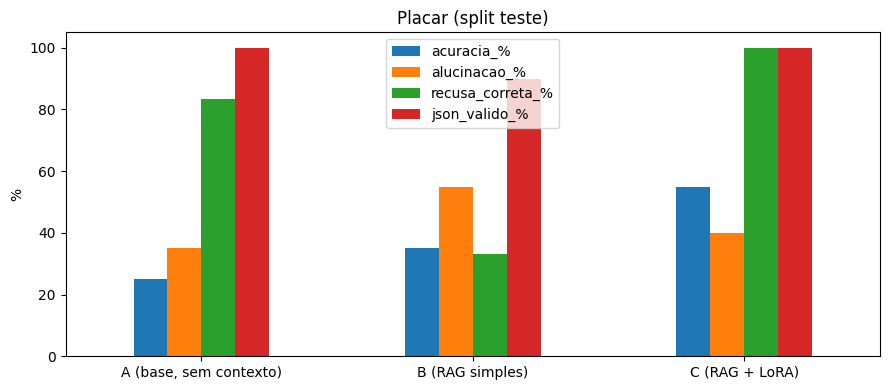

B - A [correta]: diferença=+0.100  IC95%=(-0.200, +0.400)  n=20
B - A [alucinacao]: diferença=+0.200  IC95%=(-0.100, +0.500)  n=20
C - B [correta]: diferença=+0.200  IC95%=(+0.050, +0.400)  n=20
C - B [alucinacao]: diferença=-0.150  IC95%=(-0.300, +0.000)  n=20
C - A [correta]: diferença=+0.300  IC95%=(+0.100, +0.500)  n=20
C - A [alucinacao]: diferença=+0.050  IC95%=(-0.200, +0.300)  n=20

IC que contém 0 => com 20 perguntas não dá para afirmar diferença real.


In [8]:
import matplotlib.pyplot as plt
cols = ["acuracia_%", "alucinacao_%", "recusa_correta_%", "json_valido_%"]
placar_teste[cols].plot.bar(figsize=(9, 4), rot=0, title="Placar (split teste)"); plt.ylabel("%"); plt.tight_layout()
plt.savefig(ROOT / "avaliacao" / "placar.png", dpi=120); plt.show()

a, b, c = (teste[k] for k in R)
for nome, x, y in [("B - A", a, b), ("C - B", b, c), ("C - A", a, c)]:
    for chave in ("correta", "alucinacao"):
        r = bootstrap_diff(x, y, key=chave)
        print(f"{nome} [{chave}]: diferença={r['diff']:+.3f}  IC95%=({r['ic95'][0]:+.3f}, {r['ic95'][1]:+.3f})  n={r['n']}")
print("\nIC que contém 0 => com 20 perguntas não dá para afirmar diferença real.")

In [9]:
# por tipo de pergunta (todas as 40, para ver onde cada configuração falha)
its = {json.loads(l)["id"]: json.loads(l) for l in open(config.TESTSET_PATH, encoding="utf-8")}
linhas = []
for nome, rows in R.items():
    for r in rows:
        linhas.append({"config": nome, "tipo": its[r["id"]]["tipo"], "correta": r["correta"], "alucinacao": r["alucinacao"]})
display(pd.DataFrame(linhas).groupby(["config", "tipo"])[["correta", "alucinacao"]].mean().round(2).unstack(0))

correta                                 \
config       A (base, sem contexto) B (RAG simples) C (RAG + LoRA)   
tipo                                                                 
definicao                      0.00            0.22           0.22   
fato                           0.00            0.67           0.67   
nao_consta                     0.92            0.58           1.00   
procedimento                   0.00            0.14           0.14   

                         alucinacao                                 
config       A (base, sem contexto) B (RAG simples) C (RAG + LoRA)  
tipo                                                                
definicao                      0.56            0.78           0.78  
fato                           0.33            0.33           0.25  
nao_consta                     0.08            0.17           0.00  
procedimento                   0.57            0.71           0.71

## Interpretação do placar (preencha com os números acima)
Responda em 4–6 linhas: (1) o RAG (B) acerta mais e alucina menos que o modelo sozinho (A)? (2) o LoRA (C) melhora o quê em relação a B — formato/citação, recusa, acurácia? (3) onde nenhum ajuda? (4) as diferenças são maiores que o IC95%? (5) custo/benefício: C exige treino e GPU; B só busca + prompt.

## 5 erros reais, causa e correção proposta
Erros escolhidos automaticamente dos resultados reais de B e C (um de cada tipo quando possível). A causa **confirmada** deve ser conferida olhando `recuperados`, `raw` e o trecho citado; o texto abaixo é uma hipótese por tipo de erro.

In [10]:
HIPOTESE = {
    "alucinação: respondeu pergunta fora da base": ("O limiar deixou passar um trecho parecido e o modelo extrapolou além do que o trecho diz.",
                                                    "Subir o limiar ou exigir que a resposta cite um número/termo presente no trecho (checagem pós-geração)."),
    "recusa indevida (limiar do gate)": ("O trecho certo tinha score abaixo do limiar (pergunta muito diferente da redação do documento).",
                                         "Baixar o limiar com margem calibrada ou reescrever a consulta (query expansion) antes da busca."),
    "recusa indevida (modelo)": ("O modelo não reconheceu a resposta no contexto (resposta espalhada em vários trechos).",
                                 "Aumentar k, aumentar o tamanho do trecho ou treinar mais exemplos de resposta multi-trecho."),
    "resposta incorreta/incompleta": ("A resposta omitiu um fato-chave ou o trecho recuperado cobria só parte da lista.",
                                      "Aumentar k para perguntas de lista; reordenar trechos; incluir exemplos de listas completas no LoRA."),
    "citação de trecho errado": ("A resposta está certa, mas o modelo citou outro trecho recuperado.",
                                 "Validar a citação contra o texto da resposta (sobreposição lexical) e re-tentar."),
    "formato inválido": ("O modelo não produziu JSON válido nem após a nova tentativa.",
                         "Decodificação restrita a JSON (outlines/guidance) ou mais exemplos de formato no LoRA."),
}
pool = [{**r, "config": k} for k in ("B (RAG simples)", "C (RAG + LoRA)") for r in R[k]]
erros = pick_errors(pool, n=5)
tab = []
for e in erros:
    causa, fix = HIPOTESE[e["tipo_erro"]]
    tab.append({"config": e["config"], "id": e["id"], "tipo_erro": e["tipo_erro"], "pergunta": e["pergunta"],
                "resposta_do_sistema": e["resposta"][:300], "esperada": e["esperada"][:300],
                "recuperados": e["recuperados"], "causa_provavel": causa, "correcao_proposta": fix})
erros_df = pd.DataFrame(tab); display(erros_df)
json.dump(tab, open(ROOT / "avaliacao" / "erros.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print(len(tab), "erros salvos em avaliacao/erros.json")

,config,id,tipo_erro,pergunta,resposta_do_sistema,esperada,recuperados,causa_provavel,correcao_proposta
0,B (RAG simples),Q04,resposta incorreta/incompleta,Qual é a finalidade do calendário de queima de...,A finalidade do calendário de queima de uma co...,No calendário de queima são listadas as queima...,"[DOC002-p020-c046, DOC002-p033-c092, DOC002-p0...",A resposta omitiu um fato-chave ou o trecho re...,Aumentar k para perguntas de lista; reordenar ...
1,B (RAG simples),Q22,formato inválido,"Segundo o SCI-200, quando o Plano de Ação do I...",,"Nem sempre precisa ser escrito, mas deve ser c...","[DOC007-p119-c271, DOC007-p104-c215, DOC008-p1...",O modelo não produziu JSON válido nem após a n...,Decodificação restrita a JSON (outlines/guidan...
2,B (RAG simples),Q23,citação de trecho errado,"Segundo o SCI-100, o que é o Sistema de Comand...",Sistema de Comando de Incidentes (SCI) é uma f...,É uma estrutura padronizada para gerenciamento...,"[DOC006-p082-c162, DOC006-p077-c139, DOC006-p0...","A resposta está certa, mas o modelo citou outr...",Validar a citação contra o texto da resposta (...
3,B (RAG simples),Q37,alucinação: respondeu pergunta fora da base,"Qual é o tempo máximo, em minutos, que uma equ...",O tempo máximo que uma equipe de brigadistas d...,Não consta na base documental fornecida.,"[DOC005-p054-c097, DOC005-p052-c096, DOC005-p0...",O limiar deixou passar um trecho parecido e o ...,Subir o limiar ou exigir que a resposta cite u...
4,C (RAG + LoRA),Q22,recusa indevida (modelo),"Segundo o SCI-200, quando o Plano de Ação do I...",Não consta nos documentos da base de conhecime...,"Nem sempre precisa ser escrito, mas deve ser c...","[DOC007-p119-c271, DOC007-p104-c215, DOC008-p1...",O modelo não reconheceu a resposta no contexto...,"Aumentar k, aumentar o tamanho do trecho ou tr..."


5 erros salvos em avaliacao/erros.json


Depois deste notebook, rode `python -m src.make_report` para gerar o `RELATORIO.md` com as tabelas preenchidas a partir dos arquivos reais.